# 05 — Forecasting the baseline price

Predict \(P_{0,t}\) from information available on date \(t\). Other series' prices that day are allowed. The baseline price that day is not. Anything estimated from history uses only earlier dates.

The first 40 baseline dates are the fitting prefix. Scores after that are the comparison.

Five forecasts are published under `methods/` for the active `GPU_BASE_PLAN`:

* **Fixed-price index** (stage 03). The lowest-volatility series on the prefix, converted with the median of its past inverse index. In this sample those series have a price that does not move, so the forecast is a level.
* **Moving-price index** (stage 03). The same conversion, restricted to series whose prefix price took at least five distinct values.
* **Cluster basket** (stage 04). Clusters and weights are fit on the prefix. The calmer basket is applied forward, and members missing that day are dropped.
* **Carry forward** (stage 05). The previous baseline price.
* **Ridge** (stage 05). Expanding ridge of the log baseline price on contemporaneous log prices of other series. The fit uses only earlier days.

Stage 03 found that no inverse index is calmer than a fixed other price, and a fixed other price just copies the baseline's own moves. Day-to-day changes in H100 on demand are small, so carrying the last price forward is the forecast these cross-sectional indices have to beat.


In [1]:
import sys

import matplotlib.pyplot as plt
import pandas as pd

from icx.forecast import error_table, load_published_methods, sync_forecasts
from icx.runtime import require_project_venv
from icx.store import Decision, open_store

ROOT = require_project_venv()
layout = open_store(ROOT)
print(f"Project:  {ROOT}")
print(f"Python:   {sys.executable}")
print(f"Baseline: {layout.baseline.key}")


Project:  /home/neoabs/src/gka/ICX
Python:   /home/neoabs/src/gka/ICX/.venv/bin/python
Baseline: nvidia-h100__ON_DEMAND


In [2]:
results = sync_forecasts(layout)
for method, result in results:
    print(f"{method.method_id:22} {result.decision.value:12} rows={len(result.frame)}")
again = sync_forecasts(layout)
decisions = {method.method_id: result.decision for method, result in again}
print("Second pass:", ", ".join(f"{key}={value.value}" for key, value in decisions.items()))
if any(decision is not Decision.SKIP for decision in decisions.values()):
    raise RuntimeError("Unchanged indices should reuse the stored forecasts.")

published = load_published_methods(layout)
summary = error_table(published)
print()
print(summary.to_string(index=False))


03_fixed_price         skip         rows=44
03_moving_price        skip         rows=92
04_cluster_basket      skip         rows=92
05_carry_forward       skip         rows=92
05_ridge               skip         rows=91
Second pass: 03_fixed_price=skip, 03_moving_price=skip, 04_cluster_basket=skip, 05_carry_forward=skip, 05_ridge=skip

        method_id stage               label  n      mae     rmse     mape
 05_carry_forward    05       Carry forward 92 0.025218 0.050359 0.007972
         05_ridge    05 Ridge on log prices 91 0.074726 0.090408 0.023503
  03_moving_price    03  Moving-price index 92 0.183861 0.205271 0.057407
04_cluster_basket    04      Cluster basket 92 0.185020 0.216483 0.057539
   03_fixed_price    03   Fixed-price index 44 0.426392 0.531540 0.134241


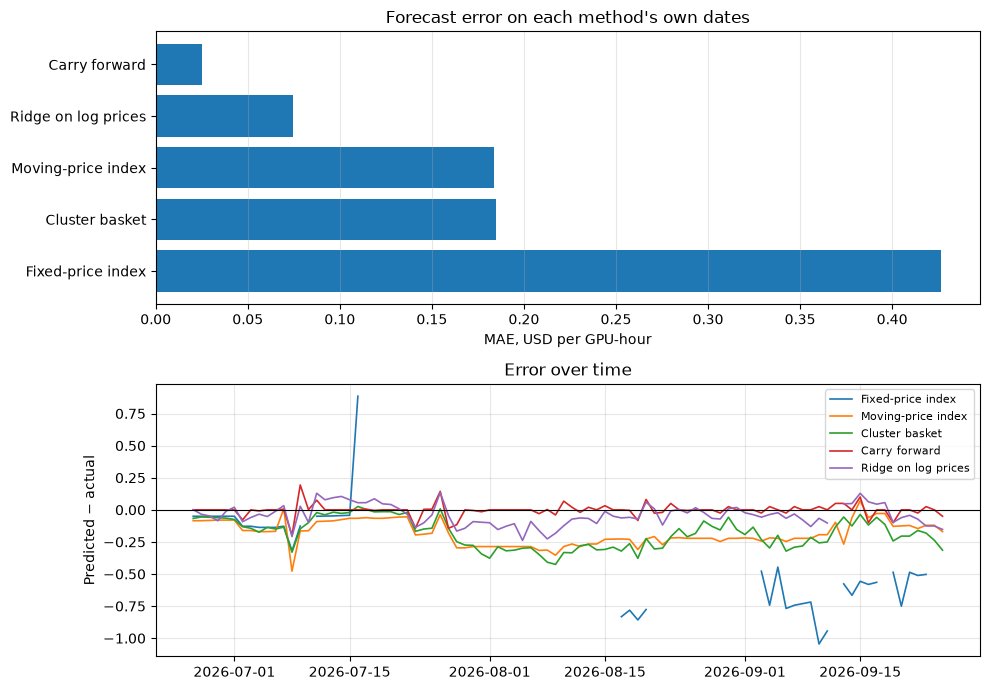

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7))
summary_plot = summary.sort_values("mae", ascending=False)
axes[0].barh(summary_plot["label"], summary_plot["mae"], color="tab:blue")
axes[0].set_xlabel("MAE, USD per GPU-hour")
axes[0].set_title("Forecast error on each method's own dates")
axes[0].grid(True, axis="x", alpha=0.3)


def plot_error(axis, frame, label):
    scored = frame.copy()
    scored["date"] = pd.to_datetime(scored["date"])
    scored["error"] = pd.to_numeric(scored["y_pred"]) - pd.to_numeric(scored["y_true"])
    scored = scored.dropna(subset=["error"]).sort_values("date")
    rows = []
    previous = None
    for row in scored.itertuples(index=False):
        if previous is not None and (row.date - previous).days > 1:
            rows.append({"date": previous + pd.Timedelta(days=1), "error": float("nan")})
        rows.append({"date": row.date, "error": row.error})
        previous = row.date
    line = pd.DataFrame(rows)
    axis.plot(line["date"], line["error"], label=label, lw=1.2)

for meta, frame in published:
    plot_error(axes[1], frame, meta["label"])
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_ylabel("Predicted − actual")
axes[1].set_title("Error over time")
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
plt.show()
